<a href="https://colab.research.google.com/github/SlukaLukas2/Neuronov-s-t-a-evolu-n-soustavy-NSES-AI---artifical-intelligence/blob/embedding/NSES_09_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision matplotlib scikit-learn fasttext

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.1.0-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.1.0-py3-none-any.whl (319 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp313-cp313-linux_x86_64.whl size=4711562 sha256=3bfab238d15f88af516a160cd3ae61e32cf9dd27adb5bddcbef20fb368a97792
  Stored in directory: /root/.cache/pip/wheels/59/06/3f/c95dbba0df6e58ba6ed18220c1aea1e96042802139df3674ef
Successfully built fasttext
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fasttext]


2. Data Preparation

In [ ]:
import json, os, re
from typing import Dict, List, Tuple, Iterable, Optional

In [ ]:
with open('NSES_1_latex.txt', 'r', encoding='utf-8') as f:
    text_full = f.read()
print(text_full[:100])
text = text_full[:2000]
text = text_full

Budeš schopný si stáhnout.
To je peklo.
Já si to tedy ještě udělám možná trochu lépe, doufám.
Včera 


In [ ]:
class SimpleWordTokenizer:
    """
    Splits text into words (Unicode-aware) and assigns each word a unique id.
    IDs are created in order of first appearance (after special tokens).
    """
    # Letters only (no digits/underscore): [^\W\d_] == all Unicode letters
    _WORD_RE = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)*", flags=re.UNICODE)

    def __init__(self, lower: bool = True, special_tokens: Optional[List[str]] = None):
        self.lower = lower
        self.word2id: Dict[str, int] = {}
        self.id2word: List[str] = []
        if special_tokens is None:
            special_tokens = ["<pad>", "<unk>"]
        self.special_tokens = list(special_tokens)
        for tok in self.special_tokens:
            self._add_word(tok)

    def fit(self, texts: Iterable[str]) -> None:
        for t in texts:
            for w in self._tokenize(t):
                if w not in self.word2id:
                    self._add_word(w)

    def encode(self, text: str, add_new: bool = True) -> List[int]:
        ids = []
        for w in self._tokenize(text):
            if w in self.word2id:
                ids.append(self.word2id[w])
            else:
                ids.append(self._add_word(w) if add_new else self.word2id.get("<unk>", 1))
        return ids

    def decode(self, ids: List[int]) -> str:
        return " ".join(self.id2word[i] if 0 <= i < len(self.id2word) else "<unk>" for i in ids)

    def _tokenize(self, text: str) -> List[str]:
        if self.lower:
            # casefold is better for Unicode (ß→ss, etc.)
            text = text.casefold()
        return self._WORD_RE.findall(text)

    def _add_word(self, word: str) -> int:
        idx = len(self.id2word)
        self.word2id[word] = idx
        self.id2word.append(word)
        return idx

    @property
    def vocab_size(self) -> int:
        return len(self.id2word)

    def save(self, path: str) -> None:
        with open(path, "w", encoding="utf-8") as f:
            json.dump({
                "lower": self.lower,
                "special_tokens": self.special_tokens,
                "id2word": self.id2word
            }, f, ensure_ascii=False)

    @classmethod
    def load(cls, path: str) -> "SimpleWordTokenizer":
        with open(path, "r", encoding="utf-8") as f:
            obj = json.load(f)
        tok = cls(lower=obj["lower"], special_tokens=obj["special_tokens"])
        tok.word2id.clear()
        tok.id2word = []
        for w in obj["id2word"]:
            tok._add_word(w)
        return tok



3. Model Definition

In [ ]:
import random
from typing import List, Iterable, Tuple
import torch
from torch.utils.data import Dataset

def make_skipgram_pairs_from_text(text: str, tokenizer):
    """
    Build (center, context) pairs directly from raw text using a tokenizer.
    """
    # Tokenize + encode
    ids = tokenizer.encode(text, add_new=False)  # don't grow vocab if already built
    return [ids]  # one sequence (the text)


def make_skipgram_pairs(sequences: Iterable[List[int]], window: int) -> List[Tuple[int, int]]:
    """
    Build (center, context) pairs from a corpus represented as a list of ID sequences.
    sequences: e.g., [[12, 45, 78], [5, 6, 7, 8], ...]
    window: symmetric window size (e.g., 2 -> look 2 tokens left/right)
    """
    pairs = []
    for ids in sequences:
        n = len(ids)
        for i, center in enumerate(ids):
            left = max(0, i - window)
            right = min(n, i + window + 1)
            for j in range(left, right):
                if j == i:
                    continue
                context = ids[j]
                pairs.append((center, context))
    return pairs

class SkipGramDataset(Dataset):
    """
    Skip-gram dataset over tokenized word-ID sequences.
    Returns (center_id, context_id) tensors.
    """
    def __init__(self, sequences: List[List[int]], window: int, shuffle_examples: bool = True):
        self.window = window
        self.pairs = make_skipgram_pairs(sequences, window)
        if shuffle_examples:
            random.shuffle(self.pairs)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        center, context = self.pairs[idx]
        return (
            torch.tensor(center, dtype=torch.long),
            torch.tensor(context, dtype=torch.long),
        )

def skipgram_collate(batch):
    """
    Collate a list of (center, context) into two 1D tensors.
    """
    centers = torch.stack([b[0] for b in batch], dim=0)
    contexts = torch.stack([b[1] for b in batch], dim=0)
    return centers, contexts


In [ ]:
import torch
import torch.nn as nn

class SkipGramModel(nn.Module):
    """
    Softmax Skip-gram: given center word id -> predict context word id.
    """
    def __init__(self, vocab_size: int, emb_dim: int):
        super().__init__()
        self.in_emb  = nn.Embedding(vocab_size, emb_dim)
        self.out_lin = nn.Linear(emb_dim, vocab_size, bias=False)

    def forward(self, centers: torch.Tensor) -> torch.Tensor:
        # centers: (B,)
        emb = self.in_emb(centers)       # (B, D)
        logits = self.out_lin(emb)       # (B, V)
        return logits


In [ ]:
from collections import Counter

words = re.findall(r"\b\w+\b", text.lower())
# Count word frequencies
counter = Counter(words)

most_common = counter.most_common(15)

print(f"Top {15} most frequent words:\n")
for word, count in most_common:
    print(f"{word:<15} → {count}")

Top 15 most frequent words:

to              → 818
je              → 535
a               → 515
jo              → 476
že              → 401
se              → 387
tak             → 310
v               → 249
na              → 233
jako            → 225
vlastně         → 223
ten             → 195
ty              → 189
tady            → 181
si              → 160


In [ ]:
tok = SimpleWordTokenizer()
tok.fit(words)
print(tok.word2id)           # {'<pad>':0,'<unk>':1,'hello':2,'world':3,'there':4}
ids = tok.encode("aktivační funkce neuronové sítě")   # grows vocab: adds 'new'
print(ids)                    # e.g. [2, 5, 3]
print(tok.decode(ids))        # "hello new world"
print(tok.vocab_size)

{'<pad>': 0, '<unk>': 1, 'budeš': 2, 'schopný': 3, 'si': 4, 'stáhnout': 5, 'to': 6, 'je': 7, 'peklo': 8, 'já': 9, 'tedy': 10, 'ještě': 11, 'udělám': 12, 'možná': 13, 'trochu': 14, 'lépe': 15, 'doufám': 16, 'včera': 17, 'jsem': 18, 'tady': 19, 'nacvičoval': 20, 'a': 21, 'teď': 22, 'úplně': 23, 'jiný': 24, 'takže': 25, 'tebe': 26, 'posunu': 27, 'tam': 28, 'jsi': 29, 'mi': 30, 'zmizel': 31, 'paráda': 32, 'spadne': 33, 'ty': 34, 'vol': 35, 'dobrý': 36, 'den': 37, 'ach': 38, 'můj': 39, 'bože': 40, 'jo': 41, 'firefox': 42, 'jednou': 43, 'neštěkujte': 44, 'kdyby': 45, 'se': 46, 'vám': 47, 'podařilo': 48, 'tak': 49, 'na': 50, 'mě': 51, 'zavolejte': 52, 'asi': 53, 'nastavím': 54, 'zpátky': 55, 'máme': 56, 'takové': 57, 'improvizované': 58, 'setup': 59, 'tohle': 60, 'chtěl': 61, 'děkujeme': 62, 'předmět': 63, 'byl': 64, 'původně': 65, 'no': 66, 'prapůvodně': 67, 'v': 68, 'ročníku': 69, 'pak': 70, 've': 71, 'zase': 72, 'proč': 73, 'prezentuje': 74, 'automaticky': 75, 'nevím': 76, 'že': 77, 'půjde

In [ ]:
# Convert to sequences of IDs (grows vocab).
sequences = make_skipgram_pairs_from_text(text, tok)

# Prepare data
window = 2                   # context_size for your model
ds = SkipGramDataset(sequences, window=window, shuffle_examples=False)
from torch.utils.data import DataLoader
loader = DataLoader(ds, batch_size=128, shuffle=False, collate_fn=skipgram_collate)

for centers, contexts in loader:
    # centers: [B], contexts: [B]
    # -> feed into your skip-gram model (with negative sampling, etc.)
    print(centers, contexts)
    print(centers.shape, contexts.shape)
    break


tensor([ 2,  2,  3,  3,  3,  4,  4,  4,  4,  5,  5,  5,  5,  6,  6,  6,  6,  7,
         7,  7,  7,  8,  8,  8,  8,  9,  9,  9,  9,  4,  4,  4,  4,  6,  6,  6,
         6, 10, 10, 10, 10, 11, 11, 11, 11, 12, 12, 12, 12, 13, 13, 13, 13, 14,
        14, 14, 14, 15, 15, 15, 15, 16, 16, 16, 16, 17, 17, 17, 17, 18, 18, 18,
        18,  4,  4,  4,  4,  6,  6,  6,  6, 19, 19, 19, 19, 20, 20, 20, 20, 21,
        21, 21, 21, 22, 22, 22, 22,  7,  7,  7,  7,  6,  6,  6,  6, 23, 23, 23,
        23, 24, 24, 24, 24, 25, 25, 25, 25,  9,  9,  9,  9, 26, 26, 26, 26, 27,
        27, 27]) tensor([ 3,  4,  2,  4,  5,  2,  3,  5,  6,  3,  4,  6,  7,  4,  5,  7,  8,  5,
         6,  8,  9,  6,  7,  9,  4,  7,  8,  4,  6,  8,  9,  6, 10,  9,  4, 10,
        11,  4,  6, 11, 12,  6, 10, 12, 13, 10, 11, 13, 14, 11, 12, 14, 15, 12,
        13, 15, 16, 13, 14, 16, 17, 14, 15, 17, 18, 15, 16, 18,  4, 16, 17,  4,
         6, 17, 18,  6, 19, 18,  4, 19, 20,  4,  6, 20, 21,  6, 19, 21, 22, 19,
        20, 22,  7, 20,

Initialize our skipgram model

In [ ]:
# Vocab size: use your tokenizer's size directly
vocab_size = tok.vocab_size          # no "+1" unless you truly added an extra id
emb_dim = 256
model = SkipGramModel(vocab_size, emb_dim)

opt = torch.optim.Adam(model.parameters(), lr=5e-3)
criterion = nn.CrossEntropyLoss()

print(model)

SkipGramModel(
  (in_emb): Embedding(3862, 256)
  (out_lin): Linear(in_features=256, out_features=3862, bias=False)
)


Training Loop

In [ ]:
epochs = 100
for epoch in range(1, epochs + 1):
    model.train()
    total_loss = 0.0
    for centers, contexts in loader:   # centers: (B,), contexts: (B,)
        opt.zero_grad()
        logits = model(centers)        # (B, V)
        loss   = criterion(logits, contexts)  # classify the true context id
        loss.backward()
        opt.step()
        total_loss += loss.item()
    print(f"Epoch {epoch:>2}  loss = {total_loss/len(loader):.4f}")

Epoch  1  loss = 7.6655
Epoch  2  loss = 6.4934
Epoch  3  loss = 6.2387
Epoch  4  loss = 6.1740
Epoch  5  loss = 5.9812
Epoch  6  loss = 5.8133
Epoch  7  loss = 5.7863
Epoch  8  loss = 5.7245
Epoch  9  loss = 5.6772
Epoch 10  loss = 5.6341
Epoch 11  loss = 5.5943
Epoch 12  loss = 5.5502
Epoch 13  loss = 5.5142
Epoch 14  loss = 5.4873
Epoch 15  loss = 5.4679
Epoch 16  loss = 5.4206
Epoch 17  loss = 5.3966
Epoch 18  loss = 5.3713
Epoch 19  loss = 5.3465
Epoch 20  loss = 5.3277
Epoch 21  loss = 5.3006
Epoch 22  loss = 5.2751
Epoch 23  loss = 5.2664
Epoch 24  loss = 5.2443
Epoch 25  loss = 5.2252
Epoch 26  loss = 5.2075
Epoch 27  loss = 5.1955
Epoch 28  loss = 5.1705
Epoch 29  loss = 5.1503
Epoch 30  loss = 5.1367
Epoch 31  loss = 5.1134
Epoch 32  loss = 5.1041
Epoch 33  loss = 5.0918
Epoch 34  loss = 5.0749
Epoch 35  loss = 5.0572
Epoch 36  loss = 5.0482
Epoch 37  loss = 5.0417
Epoch 38  loss = 5.0272
Epoch 39  loss = 5.0120
Epoch 40  loss = 5.0027
Epoch 41  loss = 4.9974
Epoch 42  loss =

Lets extract our models embeddings and project it in 2D

In [ ]:
import re
from collections import Counter
from typing import Optional, List, Tuple

import numpy as np
import torch
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# --- Config defaults (adjust if you like) ---
MIN_LEN   = 5
MIN_COUNT = 10
MAX_WORDS = 300
WORD_RE   = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)*", flags=re.UNICODE)

def tsne_visualize_embeddings_with_clusters(
    text: str,
    tok,
    model,
    min_len: int = MIN_LEN,
    min_count: int = MIN_COUNT,
    max_words: Optional[int] = MAX_WORDS,
    n_clusters: int = 8,
    cluster_on: str = "emb",           # "emb" to cluster in embedding space, "tsne" to cluster in 2D
    random_state: int = 42,
    show_labels: bool = True,
    top_words_per_cluster: int = 10
):
    """
    - Selects words by frequency/length filters from `text` (must exist in `tok`'s vocab).
    - Extracts their embeddings from `model` (uses model.in_emb or model.emb).
    - Runs t-SNE to 2D for visualization.
    - Clusters words (KMeans) in embedding space (default) or t-SNE space.
    - Plots points colored by cluster + plots 2D cluster centroids as large 'X'.

    Args:
        tok: tokenizer with word2id/id2word
        model: trained Skip-gram/CBOW model having .in_emb or .emb
    """
    # 1) Count words (Unicode-aware)
    words = WORD_RE.findall(text.casefold())
    counter = Counter(words)

    # 2) Filter by frequency & length; keep only words present in tokenizer vocab
    cand = [(w, c) for w, c in counter.items()
            if len(w) >= min_len and c >= min_count and w in tok.word2id]
    cand.sort(key=lambda x: (-x[1], x[0]))
    if max_words is not None:
        cand = cand[:max_words]

    if not cand:
        print("No words meet the filters (try lowering MIN_COUNT or MIN_LEN).")
        return

    selected_words = [w for w, _ in cand]
    selected_ids   = [tok.word2id[w] for w in selected_words]
    freqs          = dict(cand)  # for reporting

    # 3) Get the embedding table (Skip-gram uses 'in_emb'; CBOW example used 'emb')
    emb_table = getattr(model, "in_emb", getattr(model, "emb", None))
    if emb_table is None:
        raise AttributeError("Model must have 'in_emb' or 'emb' as the embedding layer.")

    model.eval()
    with torch.no_grad():
        vecs = emb_table.weight[selected_ids].detach().cpu().numpy()  # (N, D)

    # 4) t-SNE to 2D (visualization only)
    n = vecs.shape[0]
    perplexity = max(5, min(30, n - 1))  # t-SNE requires perplexity < n
    tsne = TSNE(n_components=2, perplexity=perplexity, init="random",
                learning_rate="auto", random_state=random_state)
    xy = tsne.fit_transform(vecs)  # (N, 2)

    # 5) Clustering
    if n_clusters is None or n_clusters <= 1:
        labels = np.zeros(n, dtype=int)
        colors = cm.rainbow(np.linspace(0, 1, 1))
        n_clusters = 1
    else:
        n_clusters = min(n_clusters, n)  # cannot have more clusters than points
        colors = cm.rainbow(np.linspace(0, 1, n_clusters))
        features = vecs if cluster_on == "emb" else xy
        km = KMeans(n_clusters=n_clusters, n_init="auto", random_state=random_state)
        labels = km.fit_predict(features)

    # 6) Compute cluster centroids in 2D for plotting
    centroids_2d = np.vstack([xy[labels == k].mean(axis=0) for k in range(n_clusters)])

    # 7) Plot
    plt.figure(figsize=(11, 9))
    # Scatter by cluster
    for k in range(n_clusters):
        mask = (labels == k)
        plt.scatter(xy[mask, 0], xy[mask, 1], label=f"Cluster {k} ({mask.sum()})", color=colors[k], alpha=0.8)
        if show_labels:
            for (x, y), lbl in zip(xy[mask], np.array(selected_words)[mask]):
                plt.text(x, y, lbl)

    # Plot centroids as big 'X'
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
                marker='x', s=200, linewidths=3, edgecolors='k', label="Centroids")

    plt.title(f"t-SNE of {len(selected_words)} words (len≥{min_len}, count≥{min_count})\n"
              f"Clustering: KMeans on {('embeddings' if cluster_on=='emb' else 't-SNE')} | K={n_clusters}")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend(loc="best", fontsize=9)
    plt.tight_layout()
    plt.show()

    # 8) Report top words per cluster (by corpus frequency, then alpha)
    print("\nTop words per cluster:")
    for k in range(n_clusters):
        mask_idx = np.where(labels == k)[0]
        cluster_words = [selected_words[i] for i in mask_idx]
        cluster_words.sort(key=lambda w: (-freqs[w], w))
        head = cluster_words[:top_words_per_cluster]
        print(f"\nCluster {k}  (n={len(cluster_words)}):")
        for w in head:
            print(f"  {w:<20} → {freqs[w]}")


/tmp/ipykernel_432/2502619313.py:103: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],


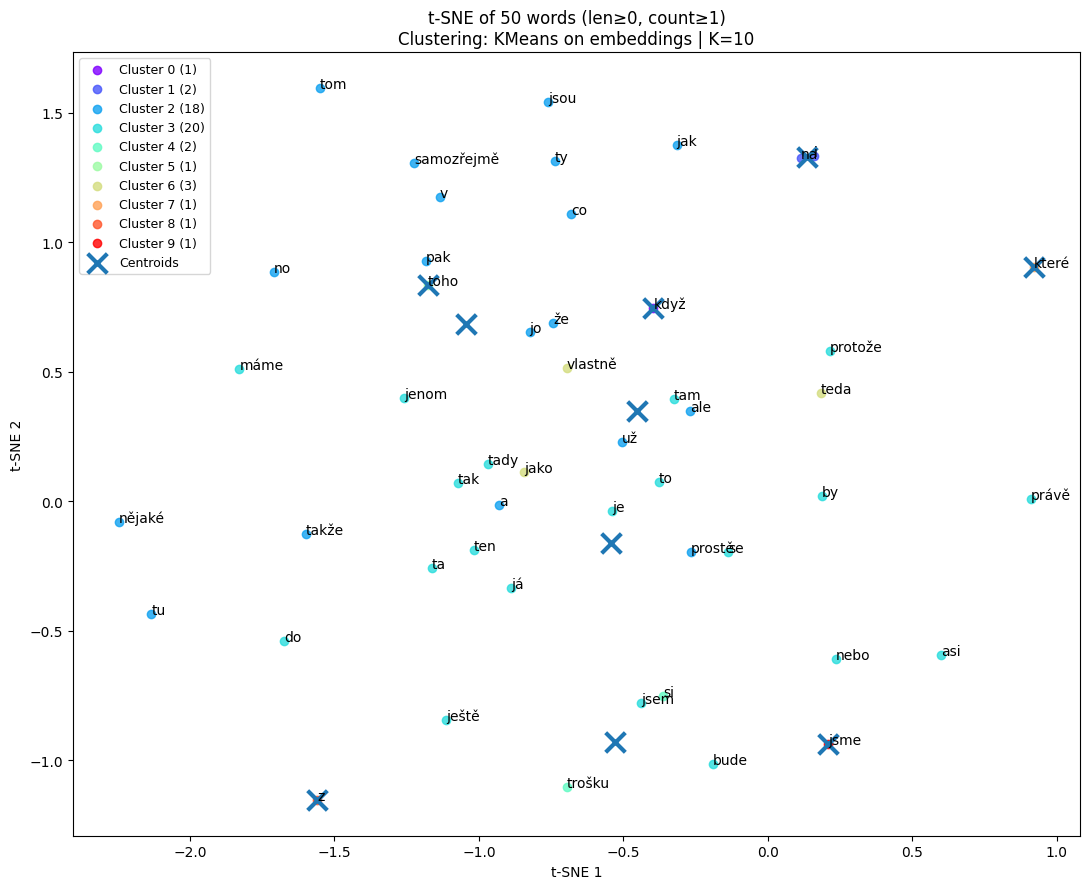


Top words per cluster:

Cluster 0  (n=1):
  když                 → 139

Cluster 1  (n=2):
  na                   → 233
  i                    → 72

Cluster 2  (n=18):
  a                    → 515
  jo                   → 476
  že                   → 401
  v                    → 249
  ty                   → 189
  takže                → 159
  ale                  → 152
  už                   → 150
  pak                  → 139
  prostě               → 132

Cluster 3  (n=20):
  to                   → 818
  je                   → 535
  se                   → 387
  tak                  → 310
  ten                  → 195
  tady                 → 181
  tam                  → 134
  já                   → 120
  do                   → 105
  ta                   → 101

Cluster 4  (n=2):
  si                   → 160
  trošku               → 56

Cluster 5  (n=1):
  toho                 → 102

Cluster 6  (n=3):
  jako                 → 225
  vlastně              → 223
  teda                 → 89

Cl

In [ ]:
# ---- Usage example ----
# text = ...  # your corpus as a single string
# tok  = ...  # your SimpleWordTokenizer (already fit)
# model = ... # your trained SkipGramModel
# tsne_visualize_embeddings(text, tok, model)

tsne_visualize_embeddings_with_clusters(
    text, tok, model,
    min_len=0, min_count=1, max_words=50,
    n_clusters=10,            # change as you like
    cluster_on="emb",        # "emb" (recommended) or "tsne"
    show_labels=True,
    top_words_per_cluster=10
)


In [ ]:
import fasttext
import fasttext.util  # optional
import numpy as np
import re
from collections import Counter
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

WORD_RE = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)*", flags=re.UNICODE)

def load_czech_fasttext(model_path: str):
    # model_path: path to .bin fastText file (binary format)
    return fasttext.load_model(model_path)

def tokenize(text: str):
    return WORD_RE.findall(text.casefold())

def tsne_visualize_czech(
    text: str,
    ft_model,  # fastText model instance
    min_len=5,
    min_count=10,
    max_words=500,
    n_clusters=10,
    random_state=42,
    show_labels=True
):
    words = tokenize(text)
    counter = Counter(words)
    cand = [(w, c) for w, c in counter.items() if len(w) >= min_len and c >= min_count]
    cand.sort(key=lambda x: (-x[1], x[0]))
    if max_words is not None:
        cand = cand[:max_words]
    if not cand:
        print("No words to visualize.")
        return

    sel_words = [w for w, _ in cand]
    freqs = dict(cand)
    # get vectors
    vecs = np.vstack([ft_model.get_word_vector(w) for w in sel_words])

    # t-SNE
    n = vecs.shape[0]
    perp = max(5, min(30, n - 1))
    tsne = TSNE(n_components=2, perplexity=perp, init="random",
                learning_rate="auto", random_state=random_state)
    xy = tsne.fit_transform(vecs)

    # clustering (on embedding space)
    k = min(n_clusters, n)
    labels = KMeans(n_clusters=k, n_init="auto", random_state=random_state).fit_predict(vecs)
    centroids = np.vstack([xy[labels == i].mean(axis=0) for i in range(k)])

    # plot
    plt.figure(figsize=(10, 8))
    for i in range(k):
        mask = labels == i
        plt.scatter(xy[mask, 0], xy[mask, 1], label=f"Cluster {i} (n={mask.sum()})", alpha=0.8)
        if show_labels:
            for (x, y), w in zip(xy[mask], np.array(sel_words)[mask]):
                plt.text(x, y, w)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=200, linewidths=3, edgecolors='k',
                label="Centroids")
    plt.title("Clustered embeddings")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    print("\nClusters and top words:")
    for i in range(k):
        ids = np.where(labels == i)[0]
        words_i = [sel_words[j] for j in ids]
        words_i.sort(key=lambda w: (-freqs[w], w))
        print(f"Cluster {i} (size {len(words_i)}): {words_i[:10]}")




In [ ]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.cs.300.bin.gz

--2026-11-09 12:15:51--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.cs.300.bin.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 99.86.101.39, 99.86.101.47, 99.86.101.24, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|99.86.101.39|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4502843070 (4.2G) [application/octet-stream]
Saving to: ‘cc.cs.300.bin.gz’

cc.cs.300.bin.gz    100%[===================>]   4.19G  45.5MB/s    in 1m 45s  

2026-11-09 12:17:36 (41.0 MB/s) - ‘cc.cs.300.bin.gz’ saved [4502843070/4502843070]



In [ ]:
!gunzip cc.cs.300.bin.gz
!pwd

/content


/tmp/ipykernel_432/2809442676.py:64: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(centroids[:, 0], centroids[:, 1],


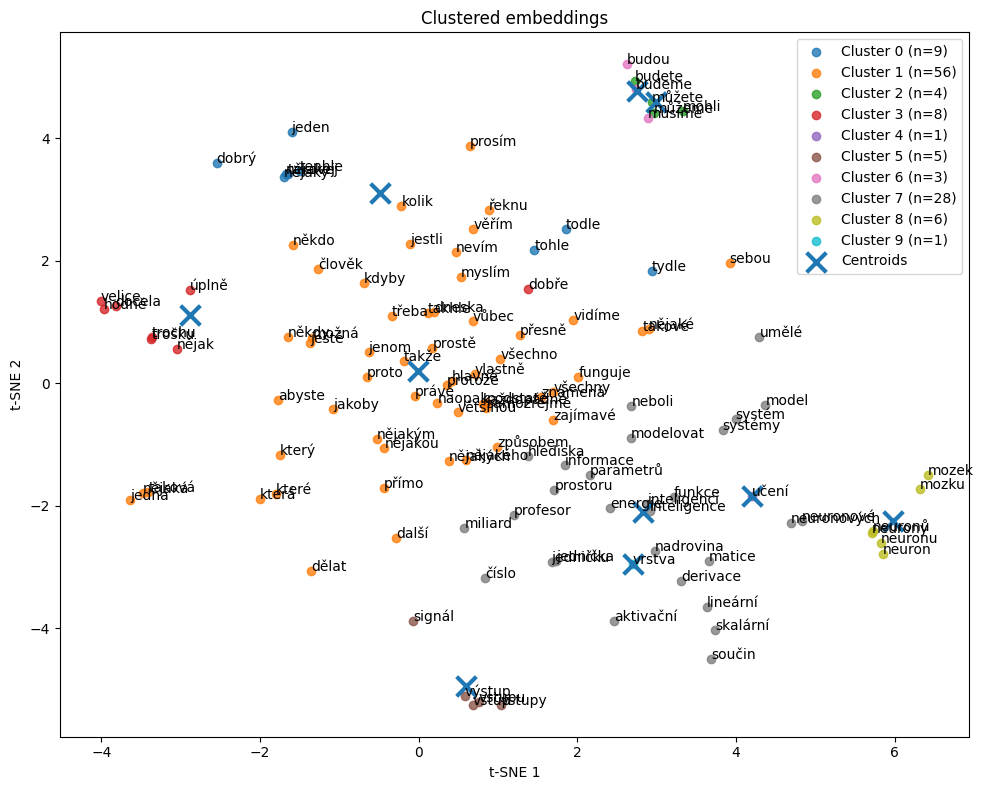


Clusters and top words:
Cluster 0 (size 9): ['nějaký', 'takovej', 'nějakej', 'dobrý', 'tenhle', 'jeden', 'todle', 'tohle', 'tydle']
Cluster 1 (size 56): ['vlastně', 'takže', 'prostě', 'samozřejmě', 'nějaké', 'právě', 'ještě', 'jenom', 'které', 'protože']
Cluster 2 (size 4): ['můžete', 'můžeme', 'budete', 'mohli']
Cluster 3 (size 8): ['trošku', 'nějak', 'dobře', 'úplně', 'velice', 'docela', 'trochu', 'hodně']
Cluster 4 (size 1): ['učení']
Cluster 5 (size 5): ['výstup', 'vstup', 'vstupu', 'vstupy', 'signál']
Cluster 6 (size 3): ['budeme', 'budou', 'musíme']
Cluster 7 (size 28): ['funkce', 'aktivační', 'neuronové', 'inteligence', 'neboli', 'lineární', 'součin', 'model', 'profesor', 'skalární']
Cluster 8 (size 6): ['neuron', 'neuronů', 'neuronu', 'neurony', 'mozek', 'mozku']
Cluster 9 (size 1): ['vrstva']


In [ ]:
# --- Usage ---
# Suppose you’ve downloaded the Czech fastText model (binary), e.g. “cc.cs.300.bin”
ft = load_czech_fasttext("/content/cc.cs.300.bin")
tsne_visualize_czech(text_full, ft)